# Logistic regression: models for yes/no answers

## Setup

In [1]:
library('tidymodels')

options(repr.plot.res = 250, repr.plot.height = 3, repr.plot.width = 5)

── Attaching packages ────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── tidymodels 1.4.1 ──
✔ broom        1.0.13     ✔ recipes      1.4.0 
✔ dials        1.4.4      ✔ rsample      1.3.2 
✔ dplyr        1.2.1      ✔ tailor       0.1.0 
✔ ggplot2      4.0.3      ✔ tidyr        1.3.2 
✔ infer        1.1.0      ✔ tune         2.1.0 
✔ modeldata    1.6.0      ✔ workflows    1.3.0 
✔ parsnip      1.6.1      ✔ workflowsets 1.1.1 
✔ purrr        1.2.2      ✔ yardstick    1.4.0 
── Conflicts ───────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── tidymodels_conflicts() ──
✖ tidyr::complete() masks hera::complete()
✖ purrr::discard()  masks scales::discard()
✖ dplyr::filter()   masks stats::filter()
✖ dplyr::lag()      masks stats::lag()
✖ recipes::step()   ma

## The data

Load the same GSS data set.

In [2]:
gss = read.csv('https://raw.githubusercontent.com/UNC-BIOS-512/jupyterlite/main/data/gss_subset.csv')

gss |> glimpse()

Rows: 75,699
Columns: 8
$ year    <int> 1972, 1972, 1972, 1972, 1972, 1972, 1972, 1972, 1972, 1972, 19…
$ id      <int> 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18,…
$ age     <int> 23, 70, 48, 27, 61, 26, 28, 27, 21, 30, 30, 56, 54, 49, 41, 54…
$ educ    <int> 16, 10, 12, 17, 12, 14, 13, 16, 12, 12, 13, 6, 9, 8, 9, 14, 14…
$ sex     <int> 2, 1, 2, 2, 2, 1, 1, 1, 2, 2, 2, 1, 1, 2, 1, 1, 1, 2, 2, 2, 1,…
$ gunlaw  <int> 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 1, NA…
$ grass   <int> NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA…
$ realinc <dbl> 18951, 24366, 24366, 30458, 50763, 43994, 37226, 13537, 2707, …


## Review: the marginal effect is the slope

The **marginal effect** of $x$ answers one question: *one more unit of $x$ gives how much more $y$?*

It is the slope of the model. In calculus words, it is the **derivative** of the model formula.

### A straight line

$$ \text{realinc} = a_1 + a_2 \times \text{educ} $$

The derivative is:

$$ \frac{d\,\text{realinc}}{d\,\text{educ}} = a_2 $$

So the marginal effect is just the slope parameter $a_2$. It is the same at every value of `educ`.

In [4]:
fit_line <- linear_reg() |> fit(realinc ~ educ, data = gss)

tidy(fit_line)

  term        estimate   std.error statistic p.value     
1 (Intercept) -14472.010 465.77481 -31.07083 1.81564e-210
2 educ          3575.967  34.43809 103.83754  0.00000e+00

The `educ` estimate is the marginal effect: about $3,600 for each year of education.

### A curve

$$ \text{realinc} = a_1 + a_2 \times \text{age} + a_3 \times \text{age}^2 $$

The derivative is:

$$ \frac{d\,\text{realinc}}{d\,\text{age}} = a_2 + 2 \times a_3 \times \text{age} $$

Now `age` is in the answer. The marginal effect **depends on the value of age**.

In [5]:
gss_age <- gss |> filter(age < 90)

fit_curve <- linear_reg() |> fit(realinc ~ age + I(age^2), data = gss_age)

a <- tidy(fit_curve)$estimate

a

[1] -11098.74993   2055.21526    -21.10516

In [9]:
a[2]

[1] 2055.215

In [7]:
tibble(age = c(25, 40, 55, 65)) |>
    mutate(me = a[2] + 2 * a[3] * age)

  age me       
1 25   999.9570
2 40   366.8021
3 55  -266.3529
4 65  -688.4562

At 25, one more year adds about 1,000 dollars. At 65, it takes away about 700 dollars. Same model, different answers.

The rule to keep:

1. For a straight line, the marginal effect is the slope parameter.
2. For any other shape, the marginal effect depends on where you are.

### Review: `lead()`

You do not need calculus to find a marginal effect. You can predict at $x$ and at $x + 1$, then take the difference.

The dplyr function `lead()` helps with this. It gets the value from the **next row**.

In [10]:
tibble(x = c(10, 20, 35, 50)) |>
    mutate(next_x = lead(x), diff = lead(x) - x)

  x  next_x diff
1 10 20     10  
2 20 35     15  
3 35 50     15  
4 50 NA     NA  

Each row gets the value from the row below it. The last row has no row below it, so it gets `NA`.

`lead(x) - x` is "next value minus this value". (`lag()` does the opposite. It gets the value from the row above.)

Now use it on the curve. Predict at every age from 18 to 85. Then `lead(.pred) - .pred` is the change from one age to the next: the marginal effect.

In [11]:
grid_age <- tibble(age = 18:85)

grid_age |> head()

  age
1 18 
2 19 
3 20 
4 21 
5 22 
6 23 

In [12]:
preds_age <- fit_curve |>
    predict(new_data = grid_age) |>
    bind_cols(grid_age) |>
    mutate(me = lead(.pred) - .pred)

preds_age |> filter(age %in% c(25, 40, 55, 65))

  .pred    age me       
1 27090.90 25   978.8518
2 37341.60 40   345.6969
3 38094.97 55  -287.4581
4 33320.92 65  -709.5614

These numbers are close to the derivative numbers above. They differ by about $20. The difference from 25 to 26 measures the slope at 25.5, not at exactly 25.

**Important:** the rows must be in order and one unit apart. If the grid jumps from 9 to 15, `lead()` gives a six-year change, not a one-year change.

## A yes/no outcome

`grass` asks: should marijuana be legal? 1 means yes, 2 means no, and `NA` means the question was not asked that year.

Drop the rows with missing values. Then make `yes`: 1 for yes, 0 for no. `yes` is a number, so we can use it in our own functions.

In [14]:
# yes when 1 = yes and 0 = no

In [13]:
# grass when 1 = yes and 2 = no

In [16]:
gss_grass <- gss |>
    drop_na(educ, grass) |>
    mutate(yes = if_else(grass == 1, 1, 0))

gss_grass |> count(yes)

  yes n    
1 0   26198
2 1   13243

### Look at the data

Every point is at 0 or at 1. They pile up on top of each other. `geom_jitter()` moves each point up and down a little, so we can see all of them.

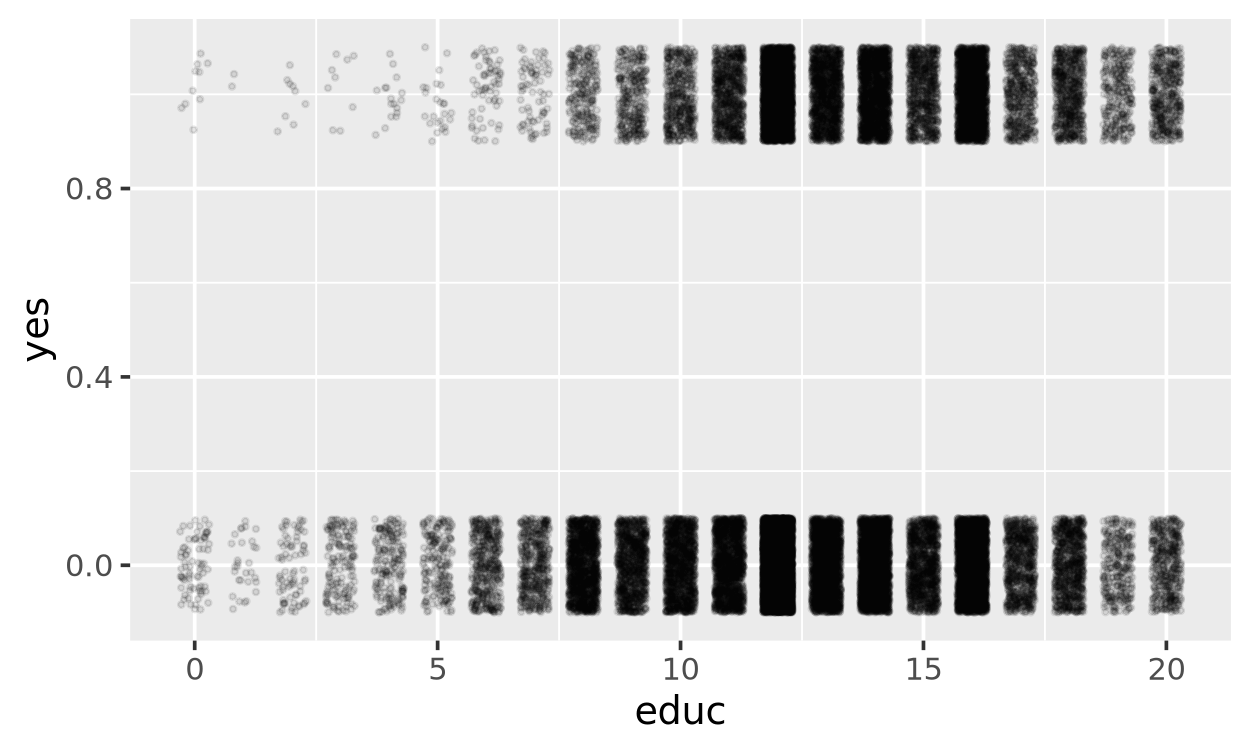

In [17]:
p_jitter <- ggplot(gss_grass, aes(x = educ, y = yes)) +
    geom_jitter(width = 0.3, height = 0.1, alpha = 0.1, size = 0.5)

p_jitter

Look at the left side and the right side. More people with many years of education say yes.

## Try a straight line

Fit a line, like we did for income.

$$ \text{yes} = a_1 + a_2 \times \text{educ} $$

In [18]:
fit_lm <- linear_reg() |> fit(yes ~ educ, data = gss_grass)

a_lm <- tidy(fit_lm)$estimate

a_lm
# fit_lm

[1] 0.004085313 0.025733377

Draw the line over the data. We make the x-axis go from -10 to 40, so we can see what the line does far away. The dashed lines are at 0 and 1.

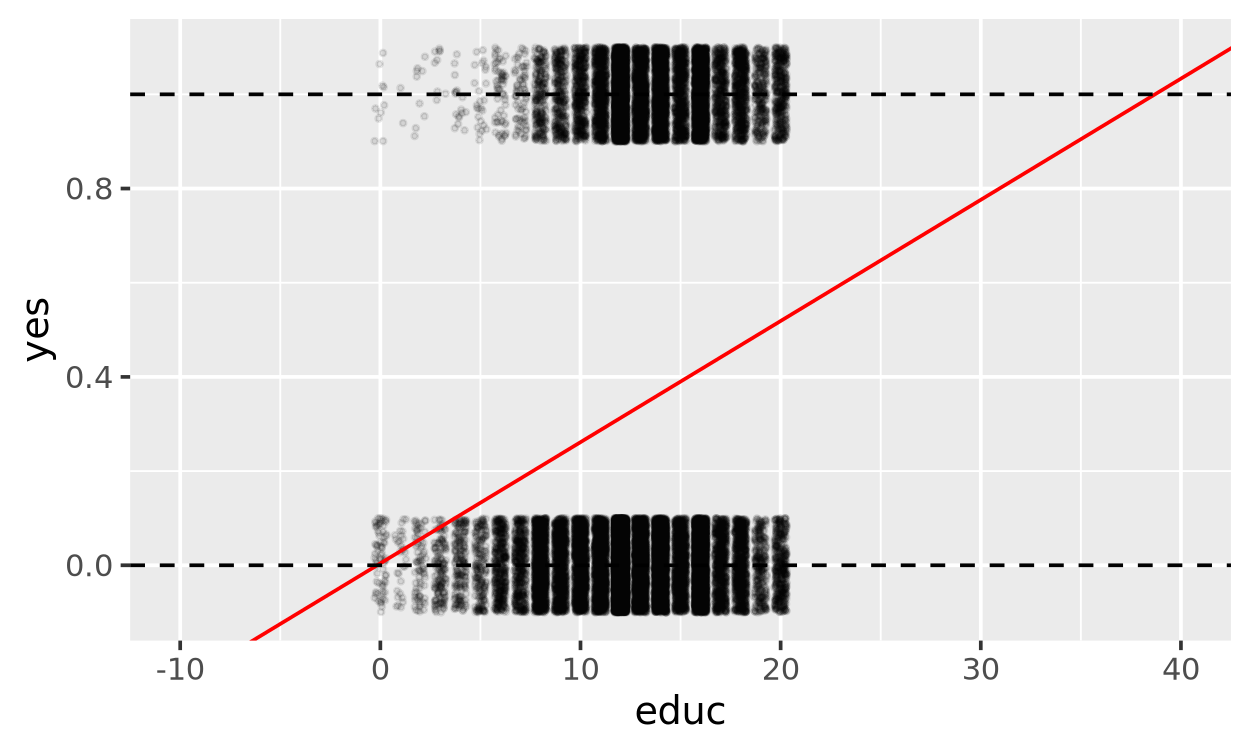

In [19]:
p_jitter +
    geom_abline(intercept = a_lm[1], slope = a_lm[2], color = 'red') +
    geom_hline(yintercept = c(0, 1), linetype = 'dashed') +
    expand_limits(x = c(-10, 40))

The prediction is a **probability** of yes. A probability must be between 0 and 1. The line goes below 0 on the left and above 1 on the right. It does not stop.

A straight line is the wrong **model family** here.

## The inverse logit

We need a shape that always stays between 0 and 1. The **inverse logit** function does this:

$$ \text{inv\_logit}(x) = \frac{1}{1 + e^{-x}} $$

Put in any number. You get back a number between 0 and 1.

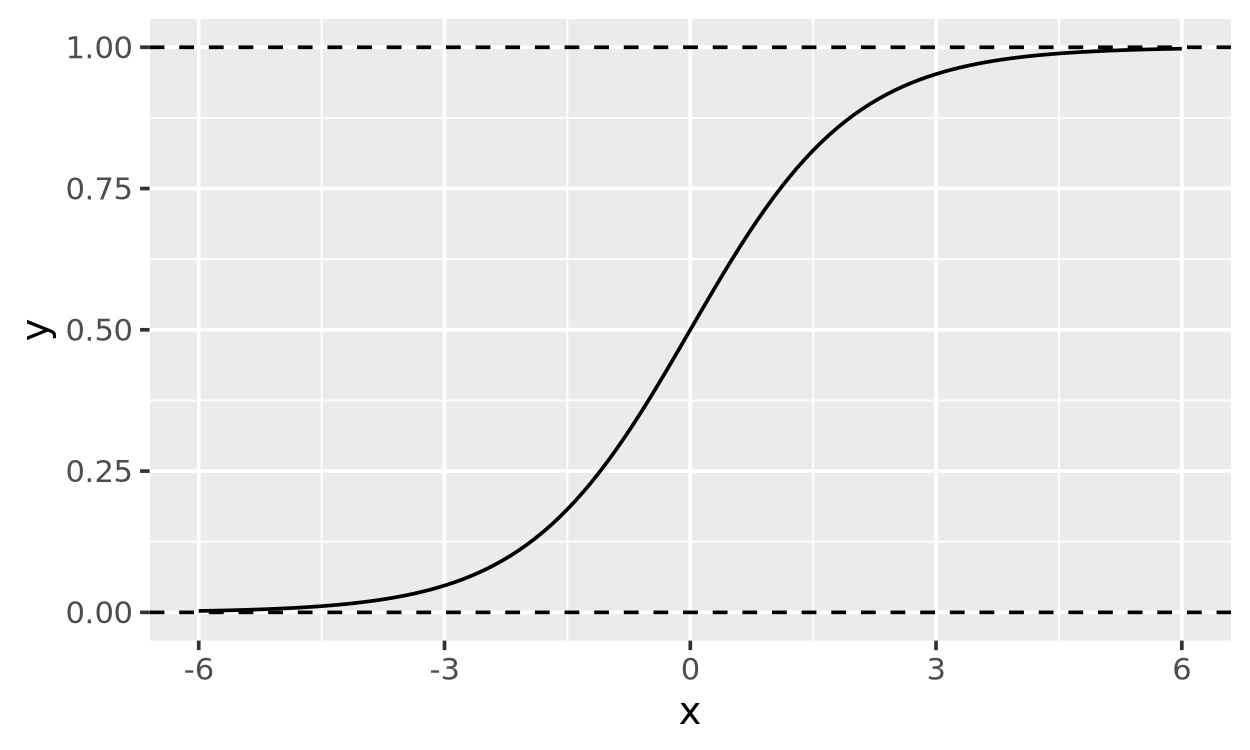

In [25]:
inv_logit <- function(x) 1 / (1 + exp(-x))

tibble(x = seq(-6, 6, by = 0.1)) |>
    mutate(y = inv_logit(x)) |>
ggplot(aes(x = x, y = y)) +
    geom_line() +
    geom_hline(yintercept = c(0, 1), linetype = 'dashed')

It is an S shape. Very negative numbers go near 0. Very positive numbers go near 1. 0 goes to 0.5.

### A quick example: penguins

Here the S shape fits very well. We use the penguins data from **modeldata** (it comes with tidymodels). Keep two species, Adelie and Chinstrap. Chinstrap penguins have longer bills.

This is a sneak peek at `logistic_reg()`. We will see how it works below.

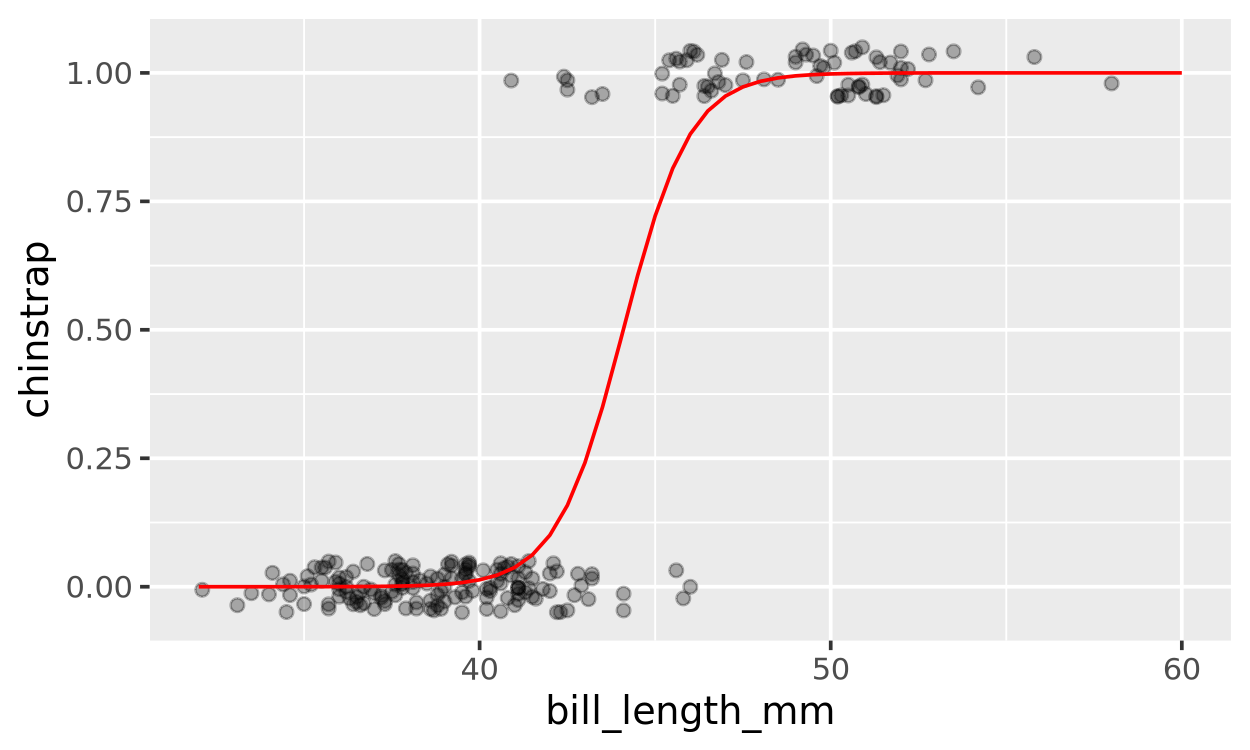

In [24]:
penguins2 <- modeldata::penguins |>
    filter(species %in% c('Adelie', 'Chinstrap')) |>
    drop_na(bill_length_mm) |>
    mutate(
        species = factor(species, levels = c('Adelie', 'Chinstrap')),
        chinstrap = if_else(species == 'Chinstrap', 1, 0)
    )

fit_peng <- logistic_reg() |> fit(species ~ bill_length_mm, data = penguins2)

grid_bill <- tibble(bill_length_mm = seq(32, 60, by = 0.5))

preds_peng <- fit_peng |>
    predict(new_data = grid_bill, type = 'prob') |>
    bind_cols(grid_bill)

ggplot(penguins2, aes(x = bill_length_mm, y = chinstrap)) +
    geom_jitter(width = 0, height = 0.05, alpha = 0.3) +
    geom_line(data = preds_peng, aes(y = .pred_Chinstrap), color = 'red')

Short bills are almost all Adelie (0). Long bills are almost all Chinstrap (1). The curve is near 0 on the left, near 1 on the right, and goes up fast where the two groups overlap.

The GSS data will not be this clean. But the idea is the same.

Now put our line *inside* the inverse logit:

$$ p = \text{inv\_logit}(a_1 + a_2 \times \text{educ}) $$

Write it as a function, like `model1()` in lecture 09.

In [26]:
model_logit <- function(a, data) {
    linear_mod = a[1] + a[2] * data$educ
    inv_logit(linear_mod)
}

Try it with the parameters from the straight line.

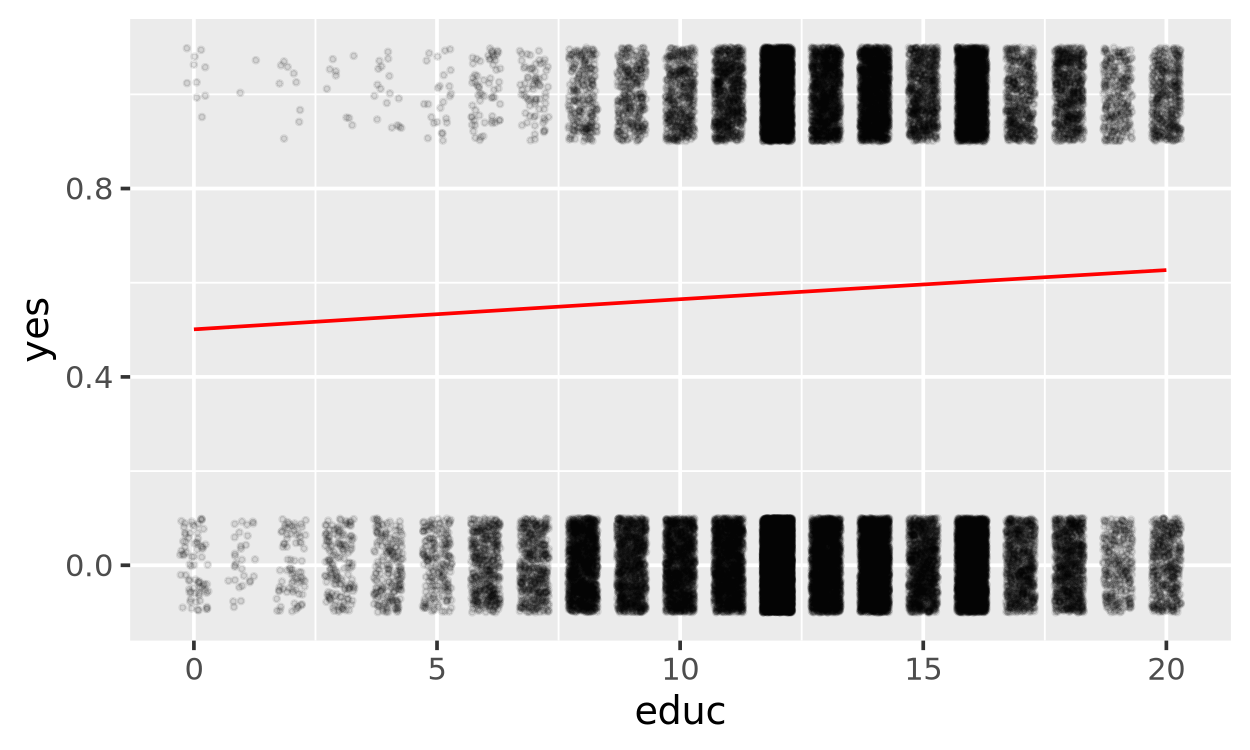

In [27]:
grid_educ <- tibble(educ = 0:20)

preds_bad <- grid_educ |> mutate(p = model_logit(a_lm, grid_educ))

p_jitter +
    geom_line(data = preds_bad, aes(y = p), color = 'red')

ind_no, educ = 2

-log( 1 - p )



ind_yes, educ = 2

-log( p ) 

The curve stays between 0 and 1. But it is a bad fit. It is almost flat, and it is too high on the left.

The problem: $a_1$ and $a_2$ were picked for a **line**. We changed the model family, but we kept the old parameters.

## Re-fit the parameters

New model family, so we must search again for $a_1$ and $a_2$. Remember the three steps from lecture 09:

1. Pick a **form** for your model. (Done: `model_logit()`.)
2. Pick a way to **measure** the fit.
3. **Search** for the best $a_1$ and $a_2$.

In [32]:
# pick some form
# input featurs / predictors
# come up with some way to calculate how well our model fits the actual data - "gain"/"loss"

# loss = RMSE
# less = sum of squared errors

# log loss

### The loss

For each person, the model gives $p$: the probability of yes.

- If the person said **yes**, we want $p$ to be big. The loss is $-\log(p)$.
- If the person said **no**, we want $1 - p$ to be big. The loss is $-\log(1 - p)$.

$-\log()$ is small when the model gives a high probability to what happened. It is very big when the model is sure and wrong. We take the **mean** over all people. This is called the **log loss**.

`case_when()` picks the right formula for each person.

In [34]:
measure_distance_logit <- function(a, data) {
    p <- model_logit(a, data)
    loss <- case_when(
        data$yes == 1 ~ -log(p),
        data$yes == 0 ~ -log(1 - p)
    )
    mean(loss)
}

measure_distance_logit(a_lm, gss_grass)

[1] 0.7565389

### The search

Give it to `optim()`, the same as in lecture 09.

In [29]:
best_logit <- optim(c(0, 0), measure_distance_logit, data = gss_grass)

best_logit$par

[1] -2.2818633  0.1222371

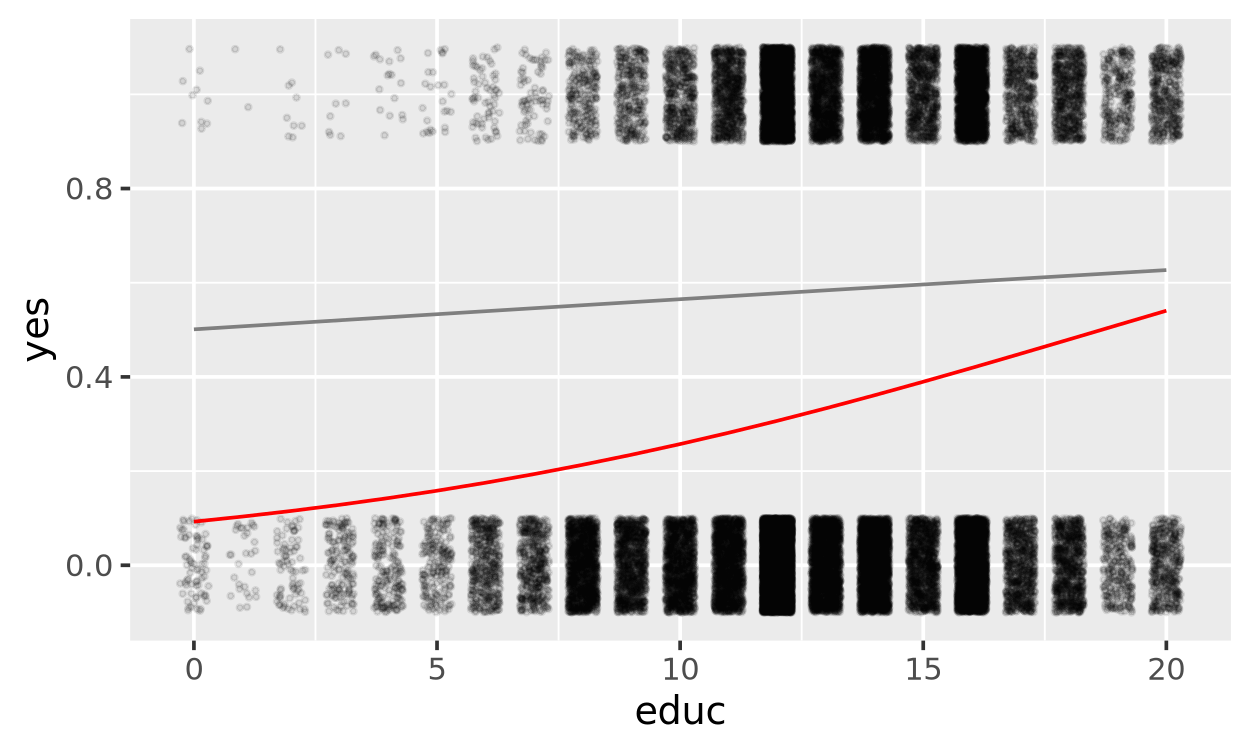

In [30]:
preds_best <- grid_educ |> mutate(p = model_logit(best_logit$par, grid_educ))

p_jitter +
    geom_line(data = preds_bad, aes(y = p), color = 'grey50') +
    geom_line(data = preds_best, aes(y = p), color = 'red')

The red curve is the new fit. It starts low and goes up with education. The grey curve is the old one, with the line's parameters.

In [35]:
# loss function -> logistic regression
# loss function -> linear regression

## `logistic_reg()`

This model has a name: **logistic regression**. tidymodels fits it with `logistic_reg()`.

In tidymodels, a yes/no outcome must be a **factor**. We put `no` first so that `yes` is the event the model predicts.

In [36]:
gss_grass <- gss_grass |>
    mutate(grass_f = factor(grass, levels = c(2, 1), labels = c('no', 'yes')))

fit_logit <- logistic_reg() |> fit(grass_f ~ educ, data = gss_grass)

tidy(fit_logit)

  term        estimate   std.error  statistic p.value      
1 (Intercept) -2.2829627 0.04955309 -46.07105  0.000000e+00
2 educ         0.1223088 0.00364240  33.57917 3.379128e-247

In [37]:
best_logit$par

[1] -2.2818633  0.1222371

Same numbers! Again, the tiny difference is because `optim()` stops when it is "close enough".

Predict on the grid. `type = 'prob'` gives the probability of each answer. `.pred_yes` is the probability of yes.

In [38]:
preds_logit <- fit_logit |>
    predict(new_data = grid_educ, type = 'prob') |>
    bind_cols(grid_educ)

preds_logit |> head()

  .pred_no  .pred_yes  educ
1 0.9074561 0.09254385 0   
2 0.8966602 0.10333985 1   
3 0.8847646 0.11523535 2   
4 0.8716958 0.12830422 3   
5 0.8573837 0.14261632 4   
6 0.8417649 0.15823511 5   

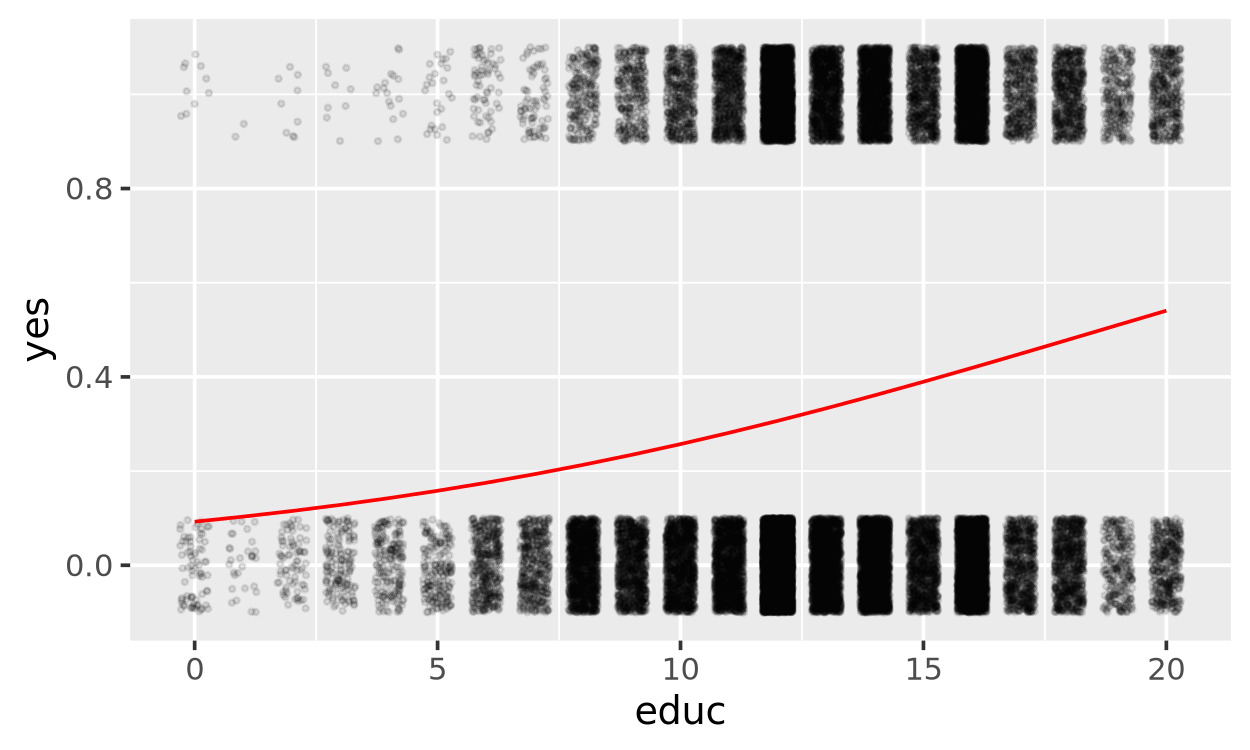

In [39]:
p_jitter +
    geom_line(data = preds_logit, aes(y = .pred_yes), color = 'red')

### Proportions by education

The jitter plot is hard to read. Plot the **share** of people who said yes at each education level. The mean of a 0/1 column is the share of 1s.

**This is for plotting only. The model is still fit on every person.**

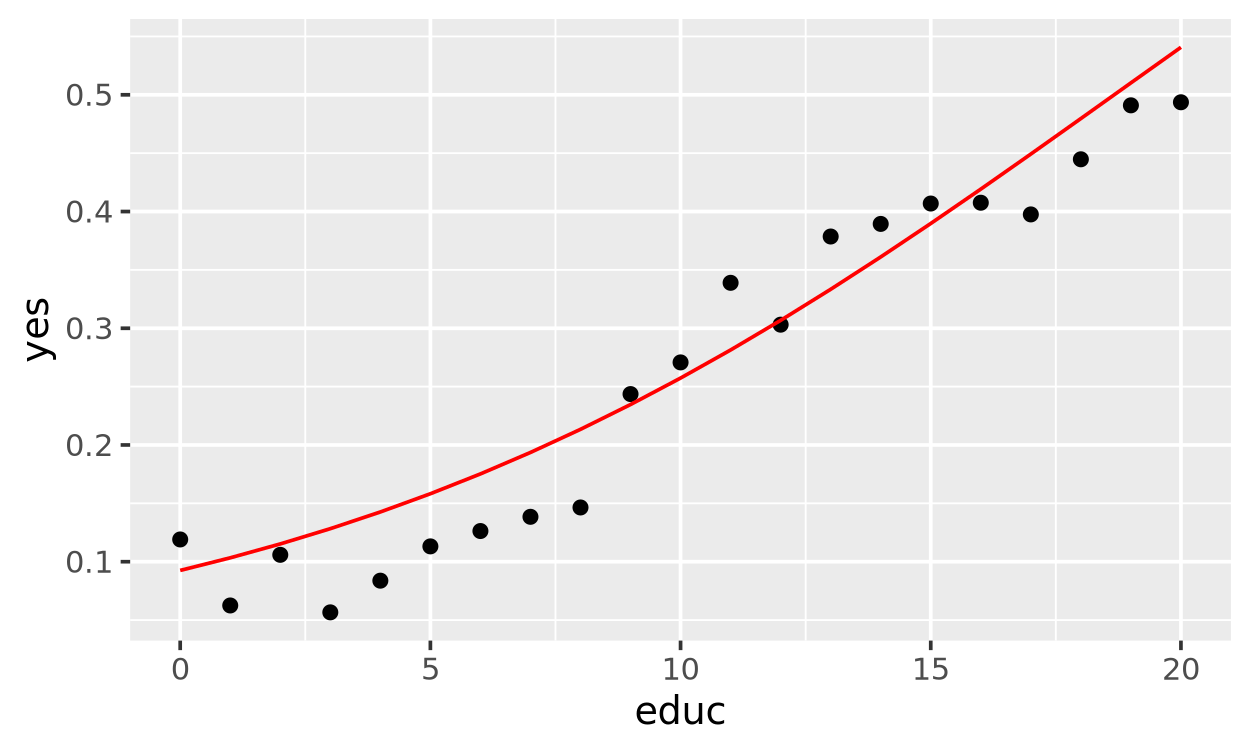

In [40]:
grass_by_educ <- gss_grass |>
    group_by(educ) |>
    summarize(yes = mean(yes))

ggplot(grass_by_educ, aes(x = educ, y = yes)) +
    geom_point() +
    geom_line(data = preds_logit, aes(y = .pred_yes), color = 'red')

The curve goes from about 0.09 at 0 years to about 0.54 at 20 years. It follows the points well. And it can never go below 0 or above 1.